# Dataset Import

Connect the Google Drive to the notebook

In [1]:
import os
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
os.chdir("/content/drive/MyDrive/dataset")

In [3]:
!pwd

/content/drive/.shortcut-targets-by-id/1NXU303Jgc2_IKKfoQvUhUL3zarWcR-bv/dataset


In [4]:
!ls

 Clothing1M  'Hotel ID'   Hotels-50k   ood_coco   Receipts  'selfie dataset'   Weapon


## Food 101

Jiawei Sun

**Tutorial:** https://datasets.activeloop.ai/docs/ml/datasets/food-101-dataset/

In [ ]:
!pip install deeplake

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 586.6/586.6 kB 12.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.3/139.3 kB 20.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 kB 10.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 65.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 65.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 16.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.1/76.1 kB 8.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.9/11.9 MB 90.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.3/139.3 kB 18.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 kB 11.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8

In [ ]:
import deeplake
food_101 = deeplake.load('hub://activeloop/food-101-dataset-train')

Opening dataset in read-only mode as you don't have write permissions.


/

This dataset can be visualized in Jupyter Notebook by ds.visualize() or at https://app.activeloop.ai/activeloop/food-101-dataset-train



|

hub://activeloop/food-101-dataset-train loaded successfully.



In [ ]:
dataloader = food_101.pytorch(num_workers=0, batch_size=4, shuffle=False)

/usr/local/lib/python3.10/dist-packages/deeplake/integrations/pytorch/common.py:137: UserWarning: Decode method for tensors ['images'] is defaulting to numpy. Please consider specifying a decode_method in .pytorch() that maximizes the data preprocessing speed based on your transformation.
  warnings.warn(


## Weapon

Jiawei Sun

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.preprocessing import LabelEncoder
from PIL import Image
import pandas as pd
import cv2

#### **Helper Functions**

In [6]:
# Get the image paths and labels with in the input folder
def get_img_path_label(target_folder):
  img_path = []
  img_label = []
  for folder_name in os.listdir(target_folder):
      folder_path = os.path.join(target_folder, folder_name)
      if os.path.isdir(folder_path):
          for image_filename in os.listdir(folder_path):
              # Construct the full path to the image file
              image_path = os.path.join(folder_path, image_filename)
              # Append the image path to the lists
              img_path.append(image_path)
              # Append the image label to the lists
              img_label.append(folder_name)
  return img_path, img_label

# Get the image resolutions and sizes of given path images
def get_img_resolutions_sizes(img_paths):
  resolutions = []
  sizes = []
  # Loop over image paths and collect data
  for img_path in img_paths:
      # Read the image using OpenCV
      img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
      # Get image resolution (height, width)
      height, width = img.shape[:2]
      resolutions.append((width, height))
      # Get image file size in bytes
      sizes.append(os.path.getsize(img_path))
  return resolutions, sizes

In [ ]:
import glob
import os
import xml.etree.ElementTree as ET

def get_xml_paths(target_folder):
  xml_file_paths = []
  xml_files = glob.glob(os.path.join(target_folder, '*.xml'))
  # Now xml_files contains a list of full file paths to the .xml files
  for file_path in xml_files:
      xml_file_paths.append(file_path)
  return xml_file_paths

def parse_xml(xml_file):
    tree = ET.parse(xml_file)
    root = tree.getroot()

    image_info = {
        'filename': root.find('filename').text,
        'size': {
            'width': int(root.find('size/width').text),
            'height': int(root.find('size/height').text),
            'depth': int(root.find('size/depth').text),
        },
        'objects': [],
    }

    for obj in root.findall('object'):
        bndbox = obj.find('bndbox')
        object_info = {
            'name': obj.find('name').text,
            'bounding_box': {
                'xmin': int(bndbox.find('xmin').text),
                'ymin': int(bndbox.find('ymin').text),
                'xmax': int(bndbox.find('xmax').text),
                'ymax': int(bndbox.find('ymax').text),
            }
        }
        image_info['objects'].append(object_info)

    return image_info

def process_xml_files(xml_files):
    all_data = []
    for xml_file in xml_files:
        data = parse_xml(xml_file)
        all_data.append(data)
    return all_data

### Pistol Classification

In [ ]:
pistol_classification = './Weapon/Pistol/Pistol_classification'

In [ ]:
# Get img paths and labels
pistol_class_img_path, pistol_class_label = get_img_path_label(pistol_classification)

#### **Label Frequency Distribution**

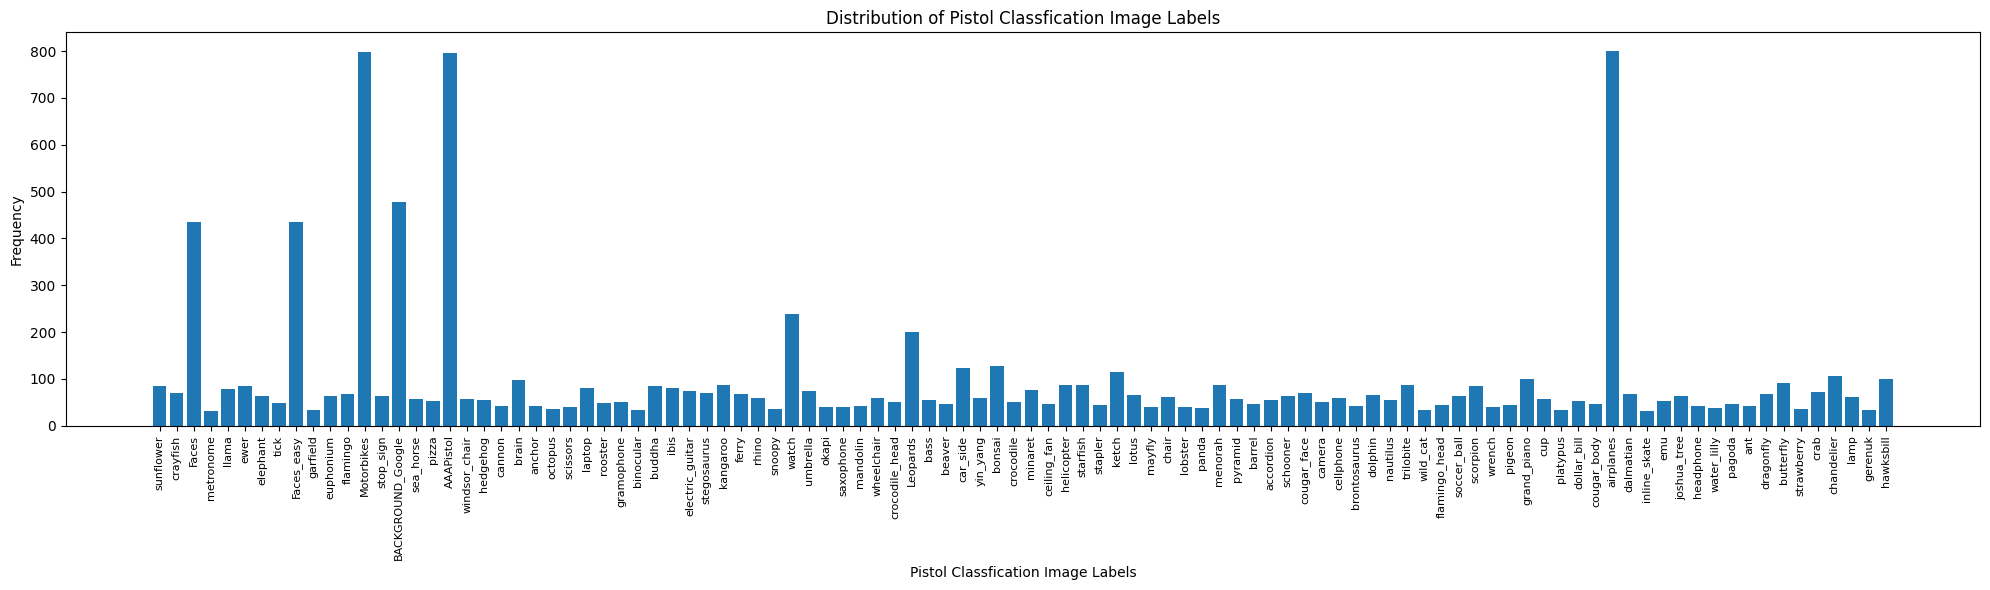

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

# Count the occurrences of each label in the list
label_counts = Counter(pistol_class_label)

# Separate the data into labels and counts
labels, counts = zip(*label_counts.items())

# Set the figure size to make the plot wider
plt.figure(figsize=(20, 6))  # Width, Height in inches

# Plotting
plt.bar(labels, counts)
plt.xlabel('Pistol Classfication Image Labels')
plt.ylabel('Frequency')
plt.title('Distribution of Pistol Classfication Image Labels')
# Rotate the x-axis labels to 90 degrees for better readability
plt.xticks(rotation=90)
# Adjust font size
plt.tick_params(axis='x', which='major', labelsize=8)
# Use a tight layout to fit the axis labels
plt.tight_layout()

plt.show()

#### **Image Resolution & Size Analyzation**

In [ ]:
# Initialize lists to store data
resolutions, sizes = get_img_resolutions_sizes(pistol_class_img_path)

# Convert lists to pandas DataFrame
df = pd.DataFrame({
    'Resolution': resolutions,
    'Size (Bytes)': sizes
})

# Add columns for width, height, and size in KB for easier analysis
df['Width'] = df['Resolution'].apply(lambda x: x[0])
df['Height'] = df['Resolution'].apply(lambda x: x[1])
df['Size (KB)'] = df['Size (Bytes)'] / 1024

# Display basic statistics
print(df.describe())

       Size (Bytes)        Width       Height    Size (KB)
count  9.877000e+03  9877.000000  9877.000000  9877.000000
mean   1.441277e+04   291.470791   235.658095    14.074973
std    2.527731e+04   100.469809    96.129440    24.684872
min    2.334000e+03    80.000000    92.000000     2.279297
25%    8.567000e+03   257.000000   171.000000     8.366211
50%    1.232400e+04   300.000000   226.000000    12.035156
75%    1.682600e+04   300.000000   300.000000    16.431641
max    1.700686e+06  3481.000000  3999.000000  1660.826172


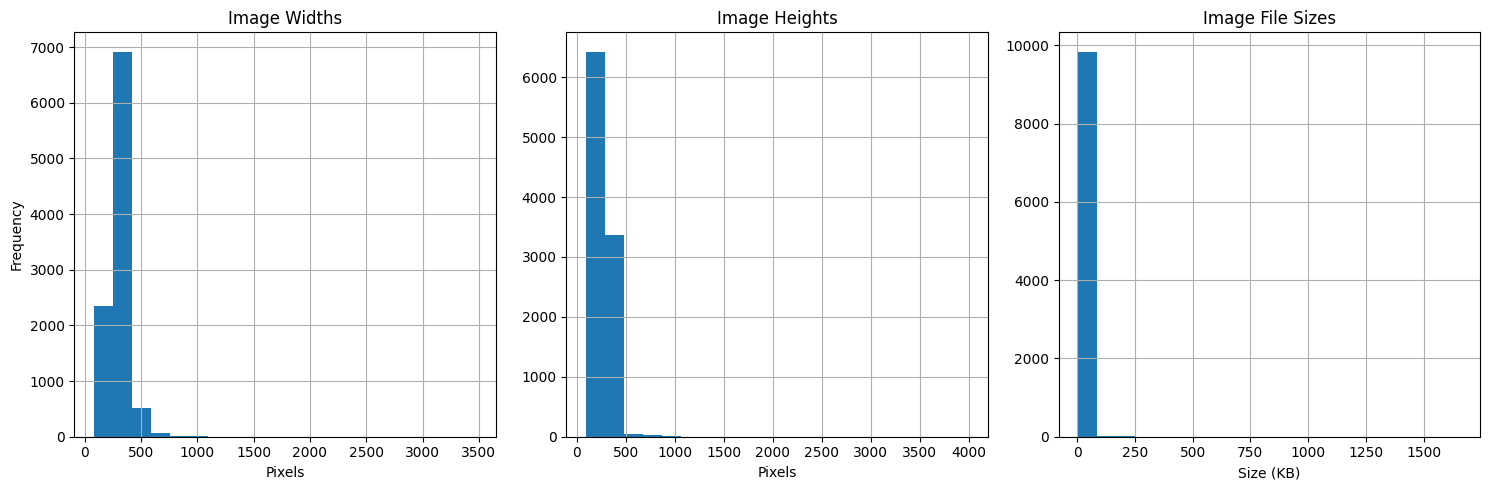

In [ ]:
# Plot histograms of widths, heights, and file sizes
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
df['Width'].hist(ax=axs[0], bins=20)
axs[0].set_title('Image Widths')
axs[0].set_xlabel('Pixels')
axs[0].set_ylabel('Frequency')

df['Height'].hist(ax=axs[1], bins=20)
axs[1].set_title('Image Heights')
axs[1].set_xlabel('Pixels')

df['Size (KB)'].hist(ax=axs[2], bins=20)
axs[2].set_title('Image File Sizes')
axs[2].set_xlabel('Size (KB)')

plt.tight_layout()
plt.show()

### Pistol Detection

In [7]:
pistol_detection = './Weapon/Pistol/Pistol_detection/xmls'

In [9]:
print(pistol_detection)

./Weapon/Pistol/Pistol_detection/xmls


#### **Width, Height, Bounding Box**

In [16]:
xml_files = get_xml_paths(pistol_detection)
all_image_data = process_xml_files(xml_files)

In [18]:
import pandas as pd

# Flatten the data
flattened_data = []
for image_data in all_image_data:
    base_info = {
        'Filename': image_data['filename'],
        'Width': image_data['size']['width'],
        'Height': image_data['size']['height'],
        'Depth': image_data['size']['depth'],
    }
    for obj in image_data['objects']:
        object_info = {
            'Object Name': obj['name'],
            'XMin': obj['bounding_box']['xmin'],
            'YMin': obj['bounding_box']['ymin'],
            'XMax': obj['bounding_box']['xmax'],
            'YMax': obj['bounding_box']['ymax'],
        }
        # Combine base info with object info and add to the flattened list
        flattened_data.append({**base_info, **object_info})

# Create the DataFrame
df_p1 = pd.DataFrame(flattened_data)

# Display the DataFrame
print(df_p1)

          Filename  Width  Height  Depth Object Name  XMin  YMin  XMax  YMax
0     armas (2307)    160     120      3      pistol     4     1   153   119
1     armas (1460)    500     375      3      pistol    26    96   498   348
2     armas (1614)    500     263      3      pistol   153   106   175   124
3       armas (46)    450     332      3      pistol   181    62   449   331
4     armas (2936)    450     420      3      pistol   146    83   220   190
...            ...    ...     ...    ...         ...   ...   ...   ...   ...
3459  armas (1927)    780     456      1      pistol   237     8   519   208
3460    armas (91)    168     113      3      pistol    69    13    76    60
3461   armas (817)    300     223      3      pistol     5    71   290   201
3462  armas (1781)    240     160      3      pistol    19    45   223   100
3463  armas (2903)    168     112      3      pistol    33    33    60    72

[3464 rows x 9 columns]


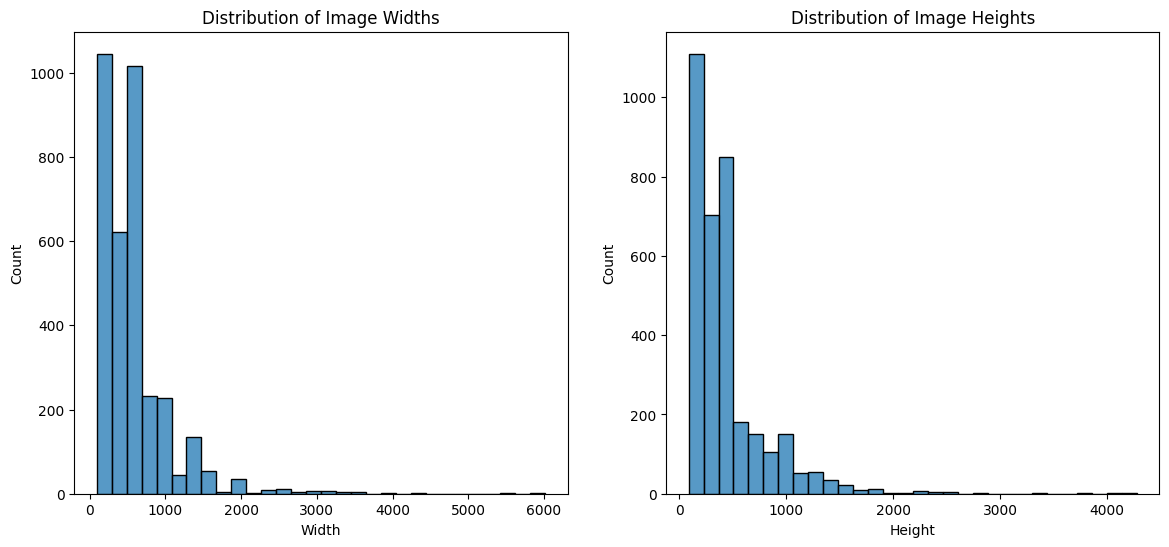

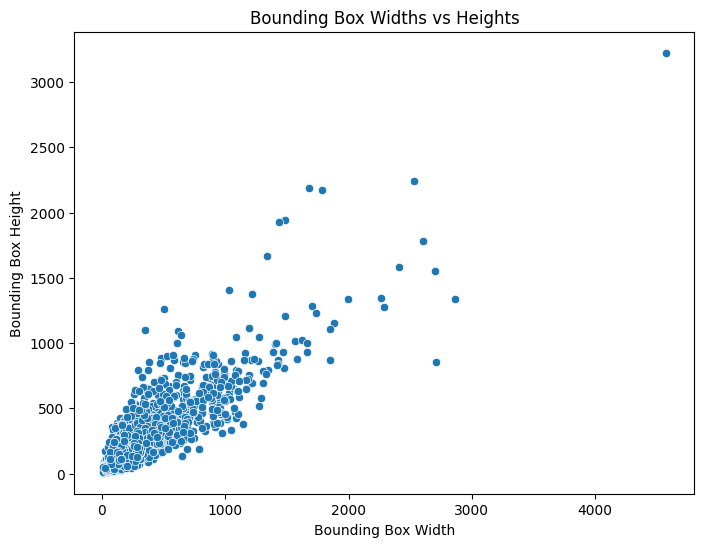

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df is the DataFrame you created from the image metadata
# And it has columns 'Width', 'Height', 'XMin', 'YMin', 'XMax', 'YMax'

# Histogram of image widths and heights
plt.figure(figsize=(14, 6))

# Subplot for Width
plt.subplot(1, 2, 1)
sns.histplot(df_p1['Width'], kde=False, bins=30)
plt.title('Distribution of Image Widths')

# Subplot for Height
plt.subplot(1, 2, 2)
sns.histplot(df_p1['Height'], kde=False, bins=30)
plt.title('Distribution of Image Heights')

plt.show()

# Scatter plot of bounding box widths vs heights
bbox_widths = df_p1['XMax'] - df_p1['XMin']
bbox_heights = df_p1['YMax'] - df_p1['YMin']

plt.figure(figsize=(8, 6))
sns.scatterplot(x=bbox_widths, y=bbox_heights)
plt.title('Bounding Box Widths vs Heights')
plt.xlabel('Bounding Box Width')
plt.ylabel('Bounding Box Height')

plt.show()

#### **Resolution, Size**

In [ ]:
# Get img paths and labels
pistol_dect_img_path = []
for image_filename in os.listdir(pistol_detection):
    # Construct the full path to the image file
    image_path = os.path.join(pistol_detection, image_filename)
    # Append the image path to the lists
    pistol_dect_img_path.append(image_path)

In [ ]:
# Initialize lists to store data
resolutions, sizes = get_img_resolutions_sizes(pistol_dect_img_path)

# Convert lists to pandas DataFrame
df_p2 = pd.DataFrame({
    'Size (Bytes)': sizes
})

# Add columns for width, height, and size in KB for easier analysis
df_p2['Size (KB)'] = df_p2['Size (Bytes)'] / 1024

# Display basic statistics
print(df_p2.describe())

       Size (Bytes)        Width       Height    Size (KB)
count  3.060000e+03  3060.000000  3060.000000  3060.000000
mean   8.504115e+04   542.203595   423.849020    83.047999
std    2.214081e+05   479.260125   373.878012   216.218851
min    1.526000e+03    94.000000    89.000000     1.490234
25%    5.501750e+03   225.000000   174.000000     5.372803
50%    3.439200e+04   460.500000   334.000000    33.585938
75%    1.000860e+05   640.000000   499.250000    97.740234
max    5.112089e+06  6016.000000  4279.000000  4992.274414


In [ ]:
# Plot histograms of widths, heights, and file sizes
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
df_p2['Size (KB)'].hist(ax=axs[2], bins=20)
axs[2].set_title('Image File Sizes')
axs[2].set_xlabel('Size (KB)')

plt.tight_layout()
plt.show()

### Knife Classificaton

In [ ]:
knife_classification = './Weapon/Knife/Knife_classification'

In [ ]:
# Get img paths and labels
knife_class_img_path, knife_class_label = get_img_path_label(knife_classification)

#### **Label Frequency Distribution**

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

# Count the occurrences of each label in the list
label_counts = Counter(knife_class_label)

# Separate the data into labels and counts
labels, counts = zip(*label_counts.items())

# Set the figure size to make the plot wider
plt.figure(figsize=(20, 6))  # Width, Height in inches

# Plotting
plt.bar(labels, counts)
plt.xlabel('Pistol Classfication Image Labels')
plt.ylabel('Frequency')
plt.title('Distribution of Pistol Classfication Image Labels')
# Rotate the x-axis labels to 90 degrees for better readability
plt.xticks(rotation=90)
# Adjust font size
plt.tick_params(axis='x', which='major', labelsize=8)
# Use a tight layout to fit the axis labels
plt.tight_layout()

plt.show()

#### **Image Resolution & Size Analyzation**

In [ ]:
# Initialize lists to store data
resolutions, sizes = get_img_resolutions_sizes(pistol_class_img_path)

# Convert lists to pandas DataFrame
df = pd.DataFrame({
    'Resolution': resolutions,
    'Size (Bytes)': sizes
})

# Add columns for width, height, and size in KB for easier analysis
df['Width'] = df['Resolution'].apply(lambda x: x[0])
df['Height'] = df['Resolution'].apply(lambda x: x[1])
df['Size (KB)'] = df['Size (Bytes)'] / 1024

# Display basic statistics
print(df.describe())

In [ ]:
# Plot histograms of widths, heights, and file sizes
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
df['Width'].hist(ax=axs[0], bins=20)
axs[0].set_title('Image Widths')
axs[0].set_xlabel('Pixels')
axs[0].set_ylabel('Frequency')

df['Height'].hist(ax=axs[1], bins=20)
axs[1].set_title('Image Heights')
axs[1].set_xlabel('Pixels')

df['Size (KB)'].hist(ax=axs[2], bins=20)
axs[2].set_title('Image File Sizes')
axs[2].set_xlabel('Size (KB)')

plt.tight_layout()
plt.show()

### Knife Detection

In [20]:
knife_detection = './Weapon/Knife/Knife_detection/annotations'

#### **Width, Height, Bounding Box**

In [ ]:
xml_files_k = get_xml_paths(knife_detection)
all_image_data_k = process_xml_files(xml_files_k)

In [ ]:
# Get img paths and labels
knife_dect_img_path = []
for image_filename in os.listdir(knife_detection):
    # Construct the full path to the image file
    image_path = os.path.join(knife_detection, image_filename)
    # Append the image path to the lists
    pistol_dect_img_path.append(image_path)

In [ ]:
import pandas as pd

# Flatten the data
flattened_data = []
for image_data in all_image_data:
    base_info = {
        'Filename': image_data['filename'],
        'Width': image_data['size']['width'],
        'Height': image_data['size']['height'],
        'Depth': image_data['size']['depth'],
    }
    for obj in image_data['objects']:
        object_info = {
            'Object Name': obj['name'],
            'XMin': obj['bounding_box']['xmin'],
            'YMin': obj['bounding_box']['ymin'],
            'XMax': obj['bounding_box']['xmax'],
            'YMax': obj['bounding_box']['ymax'],
        }
        # Combine base info with object info and add to the flattened list
        flattened_data.append({**base_info, **object_info})

# Create the DataFrame
df_k1 = pd.DataFrame(flattened_data)

# Display the DataFrame
print(df_k1)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df is the DataFrame you created from the image metadata
# And it has columns 'Width', 'Height', 'XMin', 'YMin', 'XMax', 'YMax'

# Histogram of image widths and heights
plt.figure(figsize=(14, 6))

# Subplot for Width
plt.subplot(1, 2, 1)
sns.histplot(df_k1['Width'], kde=False, bins=30)
plt.title('Distribution of Image Widths')

# Subplot for Height
plt.subplot(1, 2, 2)
sns.histplot(df_k1['Height'], kde=False, bins=30)
plt.title('Distribution of Image Heights')

plt.show()

# Scatter plot of bounding box widths vs heights
bbox_widths = df_k1['XMax'] - df_k1['XMin']
bbox_heights = df_k1['YMax'] - df_k1['YMin']

plt.figure(figsize=(8, 6))
sns.scatterplot(x=bbox_widths, y=bbox_heights)
plt.title('Bounding Box Widths vs Heights')
plt.xlabel('Bounding Box Width')
plt.ylabel('Bounding Box Height')

plt.show()

#### **Resolution, Size**

In [ ]:
# Initialize lists to store data
resolutions, sizes = get_img_resolutions_sizes(knife_dect_img_path)

# Convert lists to pandas DataFrame
df_k2 = pd.DataFrame({
    'Size (Bytes)': sizes
})

# Add columns for size in KB for easier analysis
df_k2['Size (KB)'] = df_k2['Size (Bytes)'] / 1024

# Display basic statistics
print(df_k2.describe())

In [ ]:
# Plot histograms of widths, heights, and file sizes
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

df_k2['Size (KB)'].hist(ax=axs[2], bins=20)
axs[2].set_title('Image File Sizes')
axs[2].set_xlabel('Size (KB)')

plt.tight_layout()
plt.show()

## IJB-C


"*NIST HAS DISCONTINUED DISTRIBUTION OF ALL THREE IJB CHALLENGES (IJB-A, IJB-B, AND IJB-C) ON MARCH 14TH 2023.*"


Original link: https://www.nist.gov/itl/iad/ig/ijb-c-dataset-request-form

## International Tourism Receipts

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
receipts_df = pd.read_csv('/content/drive/MyDrive/dataset/Receipts/tourism-recipts.csv')
print(receipts_df.head())

          name code  year      value_$
0  Afghanistan  AFG  2008   57000000.0
1  Afghanistan  AFG  2009   89000000.0
2  Afghanistan  AFG  2010  147000000.0
3  Afghanistan  AFG  2011  165000000.0
4  Afghanistan  AFG  2012  167000000.0


In [ ]:
# obtaining the lines for years 1995 to 2020
year_df_list = []
for year in range(1995, 2021):
    year_df_list.append(receipts_df[receipts_df["year"] == year].reset_index(drop = True))
year_df_list[ : 3]

[                                  name code  year       value_$
 0                              Albania  ALB  1995  7.000000e+07
 1                               Angola  AGO  1995  2.700000e+07
 2                            Argentina  ARG  1995  2.550000e+09
 3                              Armenia  ARM  1995  1.400000e+07
 4                                Aruba  ABW  1995  5.540000e+08
 ..                                 ...  ...   ...           ...
 134                            Uruguay  URY  1995  7.250000e+08
 135  Venezuela, Bolivarian Republic of  VEN  1995  9.950000e+08
 136            Virgin Islands, British  VGB  1995  2.110000e+08
 137               Virgin Islands, U.S.  VIR  1995  8.220000e+08
 138                           Zimbabwe  ZWE  1995  1.450000e+08
 
 [139 rows x 4 columns],
                                   name code  year       value_$
 0                              Albania  ALB  1996  9.400000e+07
 1                               Angola  AGO  1996  3.800000e+0

In [ ]:
def graph_years_top_spending_countries(years_df: pd.DataFrame, num_top_countries: int, axes = None):
    """ function which produces the bar graph for top num_top_countries in terms
    of receipt value for a given year """

    # if no axes provided, use default ones
    if axes == None:
        plt.figure(figsize = (12, 8))  # Specify your desired figure size here
        axes = plt.gca()

    # adjusting years_df if it is too large
    num_unique_countries = years_df['name'].nunique()
    num_top_countries = min(num_top_countries, num_unique_countries)

    # obtaining averages and sorting
    avg_spending = years_df.groupby('name')['value_$'].mean().reset_index()
    top_avg_spending_sorted = avg_spending.sort_values('value_$', ascending = False).head(num_top_countries)

    # graphing the results
    axes.bar(top_avg_spending_sorted['name'], top_avg_spending_sorted['value_$'])
    axes.set_xlabel('country name')
    axes.set_ylabel('avg receipts in $')
    axes.set_title(f'Top {num_top_countries} Spending Countries in {years_df["year"][0]}')
    axes.tick_params(axis = 'x', rotation = 60)


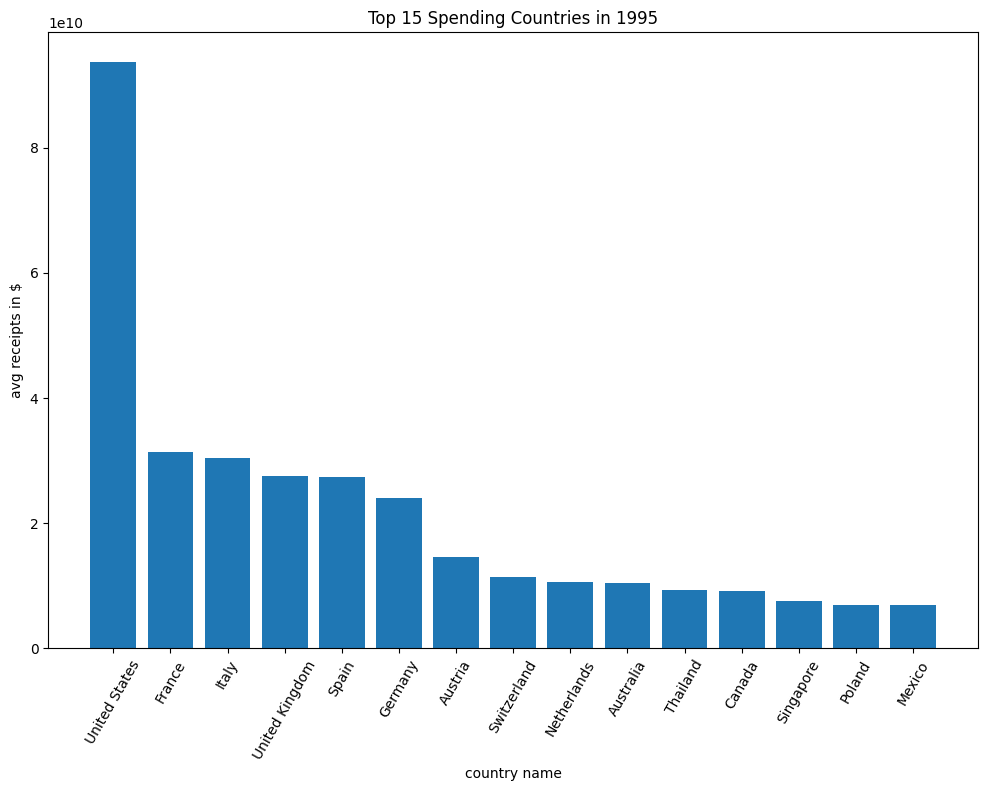

In [ ]:
# testing graph_years_top_spending_countries
graph_years_top_spending_countries(year_df_list[0], 15)

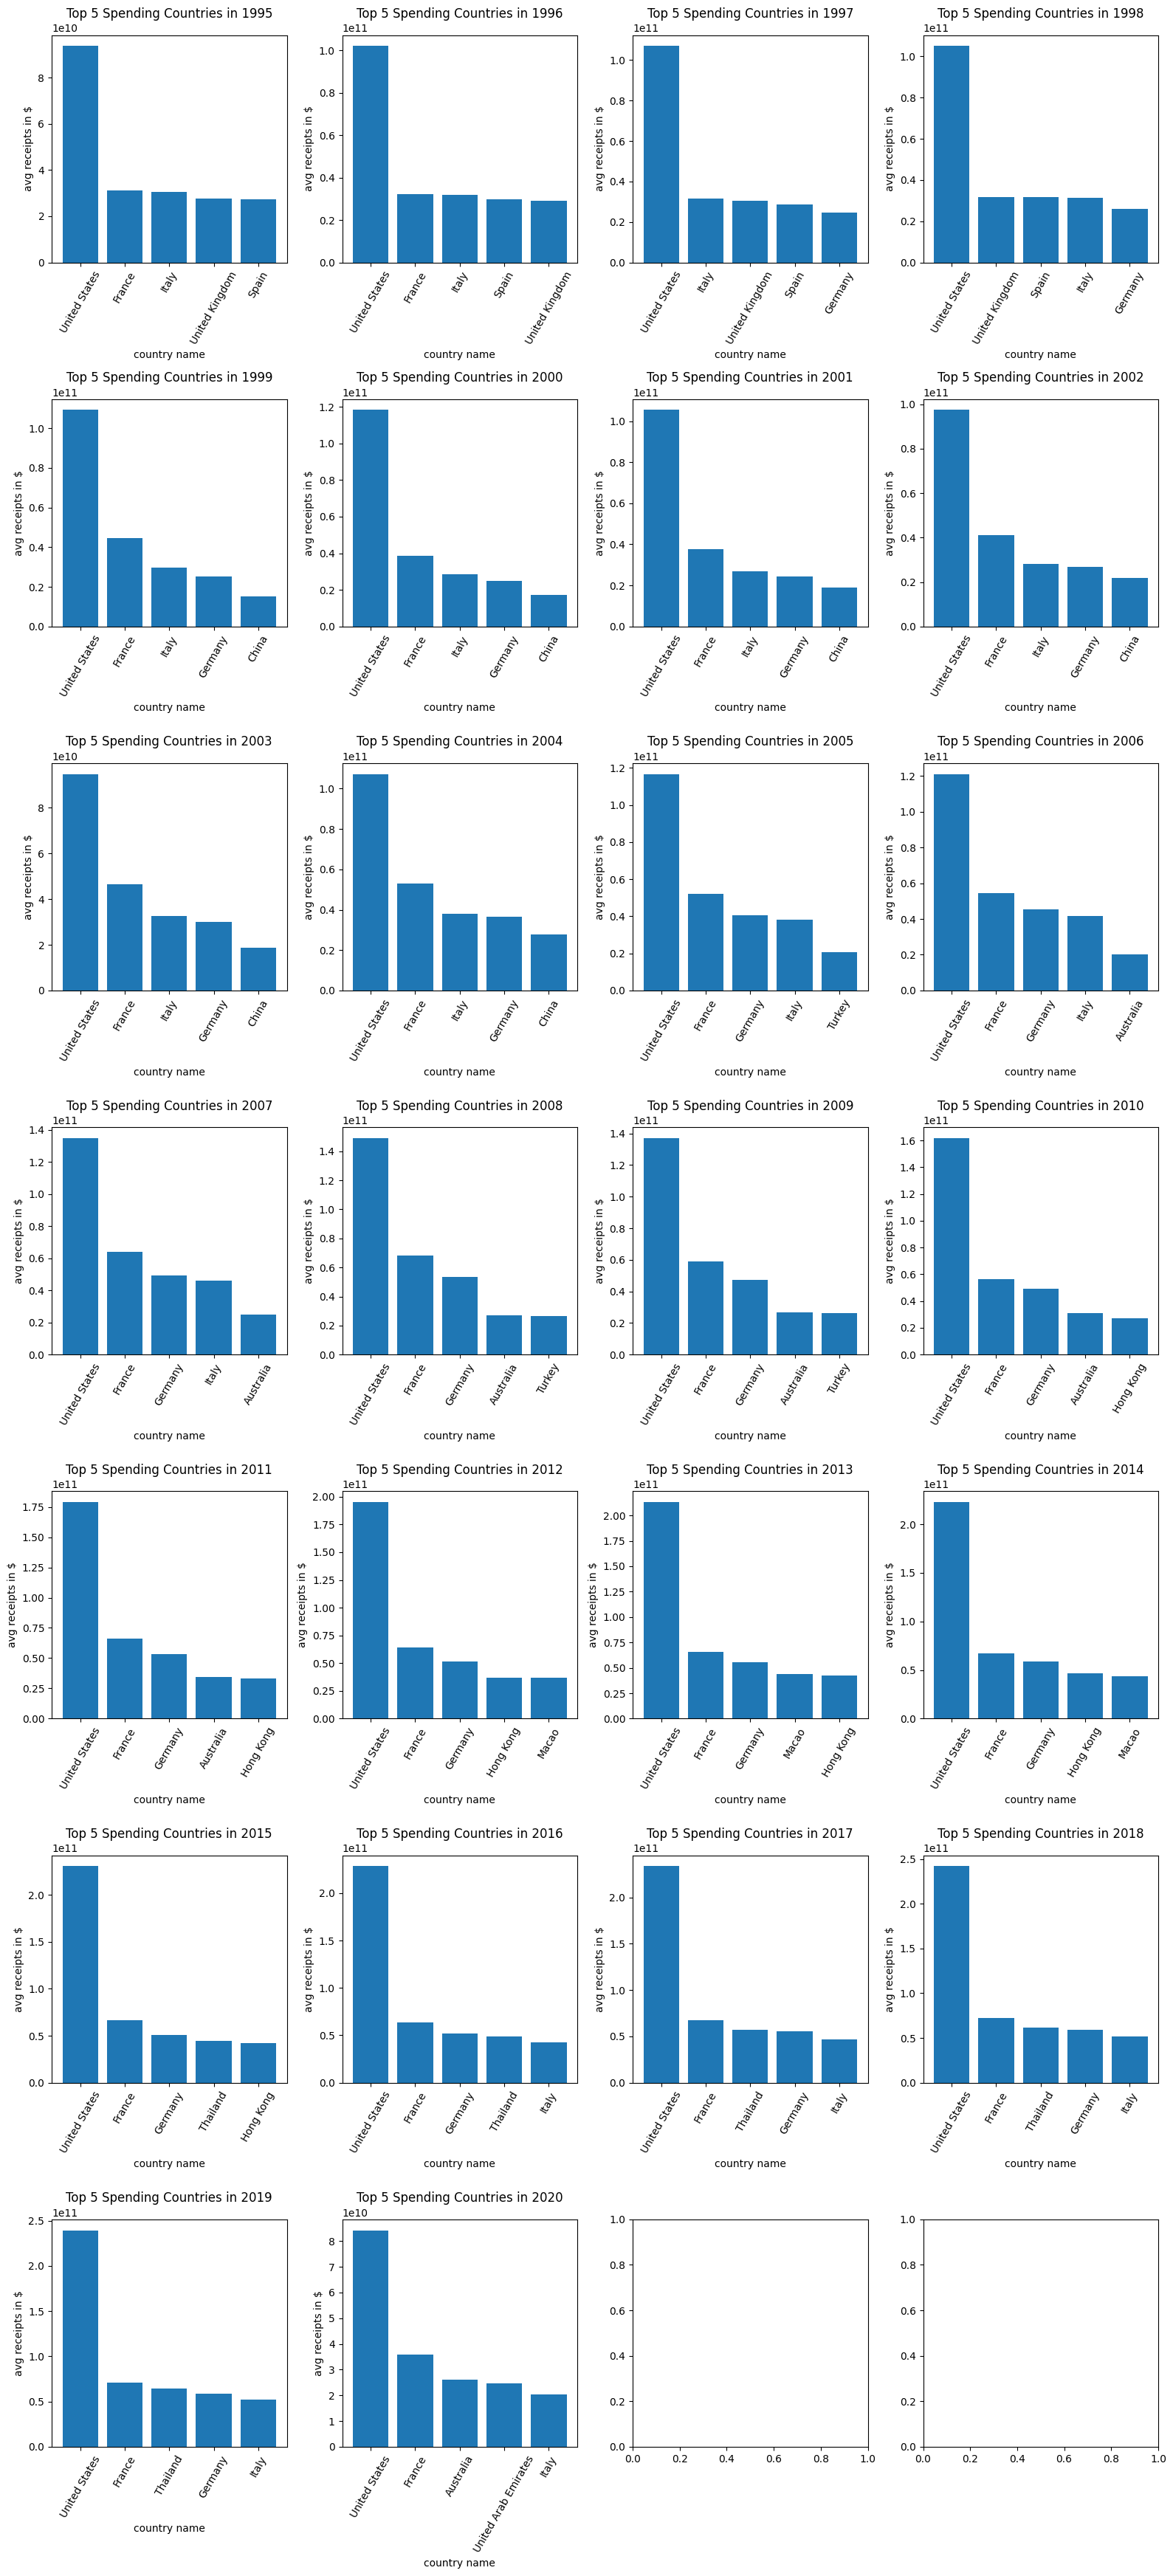

In [ ]:
# generating grid for receipt graphs for each year
num_cols = 4
num_rows = len(year_df_list) // num_cols
if num_rows * num_cols != len(year_df_list):
    num_rows += 1

# creating a grid
fig, axs = plt.subplots(num_rows, num_cols, figsize = (num_cols * 4, num_rows * 5))

# filling in the cells
for i, year in enumerate(range(1995, 2021)):
    row = i // num_cols
    col = i % num_cols
    graph_years_top_spending_countries(year_df_list[i], 5, axes = axs[row, col])

# showing the grid
plt.tight_layout()
plt.show()

In [ ]:
# average spending by country
avg_country_spendings = receipts_df.groupby("name")["value_$"].mean().reset_index().sort_values("value_$", ascending = False).reset_index(drop = True)
avg_country_spendings.head(10)

In [ ]:
# countries with historically largest receipts
plt.figure(figsize = (12, 8))
plt.bar(avg_country_spendings["name"].head(10), avg_country_spendings["value_$"].head(10))
plt.tick_params(axis = "x", rotation = 60)
plt.xlabel("country")
plt.ylabel("mean receipt in $")
plt.title("Countries with Historically Largest Receipts")
plt.show()

In [ ]:
# average spending by year
avg_year_spendings = receipts_df.groupby("year")["value_$"].mean().reset_index()
avg_year_spendings.head(10)

In [ ]:
# mean receipt values VS year
plt.figure(figsize = (12, 8))
plt.plot(avg_year_spendings["year"], avg_year_spendings["value_$"])
plt.xlabel("year")
plt.ylabel("mean receipt in $")
plt.title("Mean Receipt Values VS Year")
plt.show()

# Model training

## Weapon

Jiawei Sun

### Pistol Classfication

In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [ ]:
# Convert labels to a numerical format
le = LabelEncoder()
numerical_labels = le.fit_transform(pistol_class_label)

# Split the dataset
train_images, val_images, train_labels, val_labels = train_test_split(
    pistol_class_img_path,
    numerical_labels,
    test_size=0.2,  # 20% for validation
    stratify=numerical_labels,  # Stratify split according to the labels
    random_state=42  # Seed for reproducibility
)

# Now you can create your ImageDataGenerators for training and validation
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
def load_and_preprocess_image(image_path):
    img = load_img(image_path, target_size=(224, 224))  # Resize image
    img = img_to_array(img)
    img /= 255.0  # Normalize image
    return img

In [ ]:
# Define a simple CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(np.unique(numerical_labels)), activation='softmax')  # Number of classes
])

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])


In [ ]:
# Train the model using a custom data generator
def custom_data_generator(pistol_class_img_path, pistol_class_label, batch_size):
    while True:
        batch_paths = np.random.choice(a=pistol_class_img_path, size=batch_size)
        batch_input = []
        batch_output = []

        for input_path in batch_paths:
            input = load_and_preprocess_image(input_path)
            output = pistol_class_label[pistol_class_img_path.index(input_path)]

            batch_input.append(input)
            batch_output.append(output)

        batch_x = np.stack(batch_input, axis=0)  # Use np.stack instead of np.array
        batch_y = np.array(batch_output)

        yield batch_x, batch_y

# Training the model with a custom generator
batch_size = 32
train_generator = custom_data_generator(train_images, train_labels, batch_size)
val_generator = custom_data_generator(val_images, val_labels, batch_size)

steps_per_epoch = len(train_images) // batch_size
validation_steps = len(val_images) // batch_size

model.fit(train_generator, steps_per_epoch=steps_per_epoch, epochs=10, validation_data=val_generator, validation_steps=validation_steps)

Epoch 1/10
246/246 [==============================] - 2675s 11s/step - loss: 4.1353 - accuracy: 0.1419 - val_loss: 3.6092 - val_accuracy: 0.2859
Epoch 2/10
246/246 [==============================] - 1117s 5s/step - loss: 3.6159 - accuracy: 0.2387 - val_loss: 3.3809 - val_accuracy: 0.2982
Epoch 3/10
246/246 [==============================] - 848s 3s/step - loss: 3.4411 - accuracy: 0.2706 - val_loss: 3.2059 - val_accuracy: 0.3171
Epoch 4/10
246/246 [==============================] - 803s 3s/step - loss: 3.3003 - accuracy: 0.2854 - val_loss: 3.0407 - val_accuracy: 0.3504
Epoch 5/10
246/246 [==============================] - 794s 3s/step - loss: 3.1808 - accuracy: 0.3023 - val_loss: 3.0140 - val_accuracy: 0.3648
Epoch 6/10
179/246 [====================>.........] - ETA: 3:13 - loss: 3.0398 - accuracy: 0.3218